Cell 0: Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

Câu a) Đọc bộ dữ liệu Iris từ sklearn

In [2]:
print("Lê Anh Pha - 6451071056")

iris = load_iris()
print("Đã đọc xong bộ dữ liệu Iris")
print(type(iris))

Lê Anh Pha - 6451071056
Đã đọc xong bộ dữ liệu Iris
<class 'sklearn.utils._bunch.Bunch'>


Câu b) Khảo sát bộ dữ liệu Iris

In [3]:
print("Lê Anh Pha - 6451071056")

# Tên các thuộc tính, thuộc tính phân lớp
print("Tên các thuộc tính:", iris.feature_names)
print("Tên các lớp:", iris.target_names)

# Số lượng mẫu, số lượng thuộc tính
print("data.shape:", iris.data.shape)
print("target.shape:", iris.target.shape)
print("Số mẫu:", iris.data.shape[0], "| Số thuộc tính:", iris.data.shape[1])

# 5 mẫu đầu tiên
print("5 mẫu data đầu tiên:\n", iris.data[:5])
print("5 nhãn target đầu tiên:", iris.target[:5])

# Thống kê mô tả
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print(df.describe())

Lê Anh Pha - 6451071056
Tên các thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Tên các lớp: ['setosa' 'versicolor' 'virginica']
data.shape: (150, 4)
target.shape: (150,)
Số mẫu: 150 | Số thuộc tính: 4
5 mẫu data đầu tiên:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
5 nhãn target đầu tiên: [0 0 0 0 0]
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       peta

Câu c) Chuẩn hóa dữ liệu về đoạn [0,1]

In [4]:
print("Lê Anh Pha - 6451071056")

X = iris.data
Y = iris.target

# Lưu max của từng cột để chuẩn hóa mẫu mới ở câu i
max_values = X.max(axis=0)
print("Giá trị lớn nhất mỗi cột:", max_values)

X = X / max_values

print("Min sau chuẩn hóa:", X.min(axis=0))
print("Max sau chuẩn hóa:", X.max(axis=0))
print("5 mẫu đầu sau chuẩn hóa:\n", X[:5])

Lê Anh Pha - 6451071056
Giá trị lớn nhất mỗi cột: [7.9 4.4 6.9 2.5]
Min sau chuẩn hóa: [0.5443038  0.45454545 0.14492754 0.04      ]
Max sau chuẩn hóa: [1. 1. 1. 1.]
5 mẫu đầu sau chuẩn hóa:
 [[0.64556962 0.79545455 0.20289855 0.08      ]
 [0.62025316 0.68181818 0.20289855 0.08      ]
 [0.59493671 0.72727273 0.1884058  0.08      ]
 [0.58227848 0.70454545 0.2173913  0.08      ]
 [0.63291139 0.81818182 0.20289855 0.08      ]]


Câu d) Chia train/test theo tỷ lệ 8:2

In [5]:
print("Lê Anh Pha - 6451071056")

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

Lê Anh Pha - 6451071056
X_train: (120, 4) | y_train: (120,)
X_test : (30, 4) | y_test : (30,)


Câu e) Cây quyết định (Decision Tree)

Lê Anh Pha - 6451071056
===== Decision Tree =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



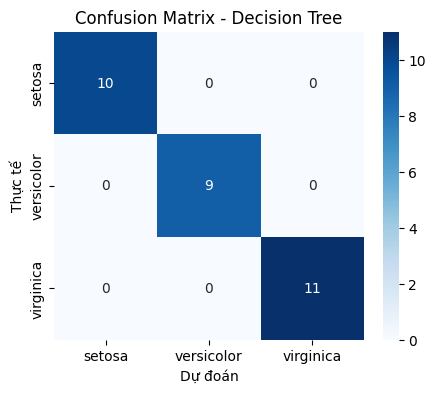

In [6]:
print("Lê Anh Pha - 6451071056")

# Hàm đánh giá dùng chung cho câu e, f, g, h
results = {}

def danh_gia(ten, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')
    results[ten] = {'Accuracy': acc, 'F1-macro': f1}

    print(f"===== {ten} =====")
    print("Accuracy:", acc)
    print(classification_report(y_true, y_pred, target_names=iris.target_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.xlabel('Dự đoán')
    plt.ylabel('Thực tế')
    plt.title(f'Confusion Matrix - {ten}')
    plt.show()

# Huấn luyện
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred_dt = dt.predict(X_test)
danh_gia("Decision Tree", y_test, y_pred_dt)

Câu f) Naïve Bayes

Lê Anh Pha - 6451071056
===== Naive Bayes =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



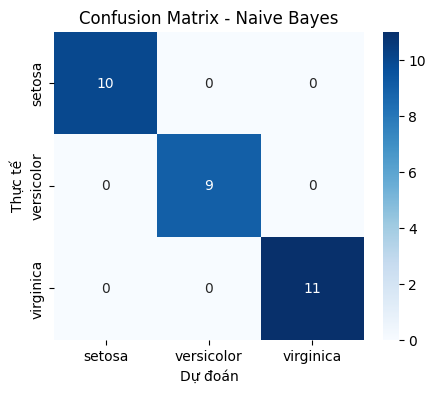

In [7]:
print("Lê Anh Pha - 6451071056")

nb = GaussianNB()
nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)
danh_gia("Naive Bayes", y_test, y_pred_nb)

Câu g) K Nearest Neighbors

Lê Anh Pha - 6451071056
===== KNN =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



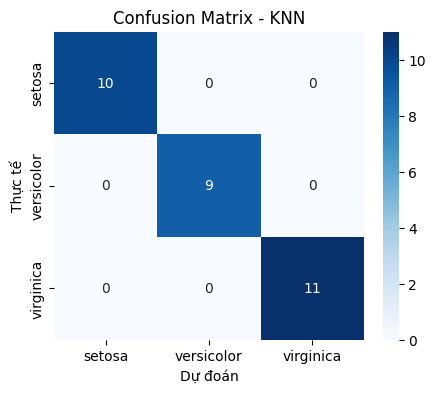

In [8]:
print("Lê Anh Pha - 6451071056")

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
danh_gia("KNN", y_test, y_pred_knn)

Câu h) Neural Network

Lê Anh Pha - 6451071056


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6250 - loss: 1.0529
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6583 - loss: 0.9880
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.9155
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.8199
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.7178
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6750 - loss: 0.6240
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7750 - loss: 0.5442
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8167 - loss: 0.4806
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9083 - loss: 0.4318
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9333 - loss: 0.3940
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.3593
Epoch 12/100
120/120 ━━━━━━━━━━━━━━━━━━━

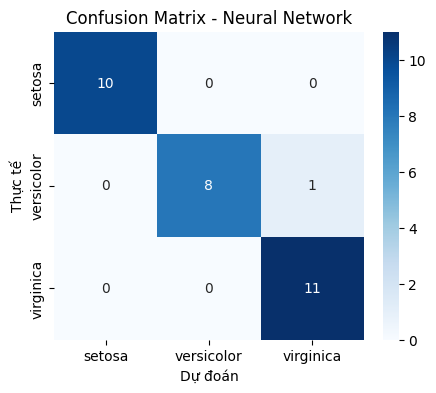

In [9]:
print("Lê Anh Pha - 6451071056")

# Xây dựng mạng: 10 neuron -> 20 neuron -> 3 neuron (softmax)
nn = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(10, activation='relu'),
    Dense(20, activation='relu'),
    Dense(3, activation='softmax')
])
nn.summary()

# Biên dịch
nn.compile(optimizer='adam',
           loss='sparse_categorical_crossentropy',
           metrics=['accuracy'])

# Huấn luyện: 100 epoch, batch_size = 1
nn.fit(X_train, y_train, epochs=100, batch_size=1, verbose=1)

# Dự đoán: predict ra xác suất, argmax chọn lớp có xác suất lớn nhất
y_pred_nn = np.argmax(nn.predict(X_test), axis=1)
danh_gia("Neural Network", y_test, y_pred_nn)

Câu i) Dự đoán 3 mẫu mới bằng cả 4 mô hình

In [10]:
print("Lê Anh Pha - 6451071056")

mau_moi = np.array([[6.2, 2.9, 4.3, 1.3],
                    [5.1, 3.5, 1.4, 0.2],
                    [7.3, 2.8, 6.4, 2.1]])

# Phải chuẩn hóa bằng CÙNG max của dữ liệu gốc (đã lưu ở câu c)
mau_moi = mau_moi / max_values

print("Decision Tree :", iris.target_names[dt.predict(mau_moi)])
print("Naive Bayes   :", iris.target_names[nb.predict(mau_moi)])
print("KNN           :", iris.target_names[knn.predict(mau_moi)])
print("Neural Network:", iris.target_names[np.argmax(nn.predict(mau_moi), axis=1)])

Lê Anh Pha - 6451071056
Decision Tree : ['versicolor' 'setosa' 'virginica']
Naive Bayes   : ['versicolor' 'setosa' 'virginica']
KNN           : ['versicolor' 'setosa' 'virginica']
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
Neural Network: ['versicolor' 'setosa' 'virginica']


Câu j) Nhận xét, đánh giá hiệu suất

Lê Anh Pha - 6451071056
                Accuracy  F1-macro
Decision Tree   1.000000  1.000000
Naive Bayes     1.000000  1.000000
KNN             1.000000  1.000000
Neural Network  0.966667  0.965899


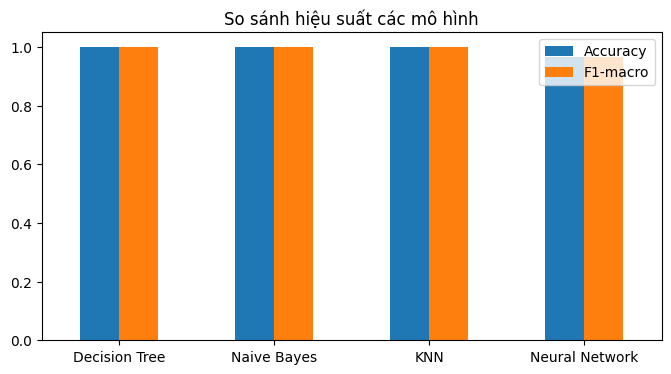

In [11]:
print("Lê Anh Pha - 6451071056")

bang_ss = pd.DataFrame(results).T
print(bang_ss)

bang_ss.plot(kind='bar', figsize=(8, 4))
plt.title('So sánh hiệu suất các mô hình')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()